Note: locate_cosmics was run in advance so this notebook is to clean up any residual cosmics. 

In [1]:
%matplotlib ipympl
reductionNo = "01"

In [2]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import reduction_utils.cosmic_removal as c
import reduction_utils.wavelength_calibration as wc

In [3]:
ls ../pickled_objects/

ls: cannot access '../pickled_objects/': No such file or directory


In [4]:
s1 = pickle.load(open(f"../../../../../data/reduction{reductionNo}/pickled_objects/star1_flux.pickle","rb"))
e1 = pickle.load(open(f"../../../../../data/reduction{reductionNo}/pickled_objects/star1_error.pickle","rb"))

In [5]:
less ../../../../../data/reduction$reductionNo/extraction_input.txt

########################
### Paths to input files

### NOTE: all .fits files must be oriented such that the dispersion direction is along the vertical axis. Run rotate_spectra.py first to do this! ###

# This is a .txt file containing the names (on separate rows) of all science frames. This can be created on the command line through  $ ls *appropriate files* > science_list. For most users this will be defined as $ ls **/*1_gainscalestep.fits > science_list. However it can be a single reference frame from which the script will load all subsequent files in cwd OR outputted by sort_ACAM_files.py/sort_EFOSC_files.py
science_list = ../../../data/science_list

# The path to the master bias .fits file. If this is not given, a frame padded with zeroes is used. This should not be defined if you're using JWST data and have performed the super bias step in stage0.
master_bias = 

# The path to the master flat .fits file. If this is not given, a frame padded with ones is used.
master_flat = 

# Th

In [6]:
s1.shape

(77373, 260)

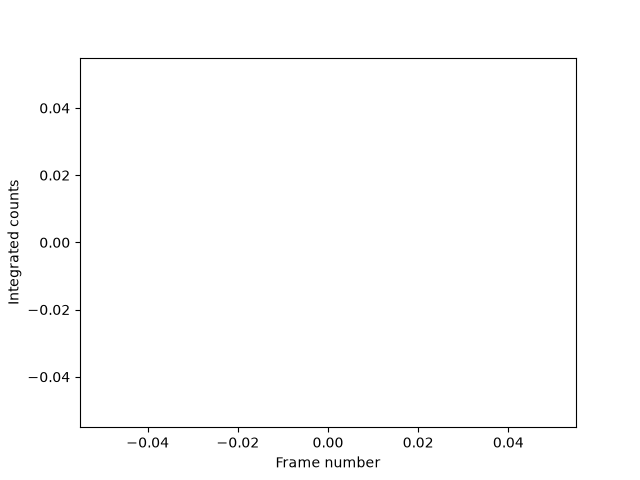

In [7]:
plt.figure()
plt.plot(s1.sum(axis=1),'k.')
plt.xlabel("Frame number")
plt.ylabel("Integrated counts")
plt.show()

/data2/ju126/miniforge3/envs/Tiberius/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


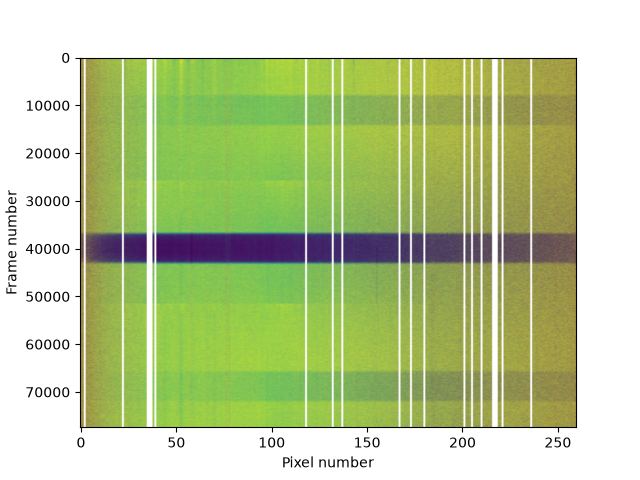

In [9]:
plt.figure()

normalised_spectra = s1/np.nanmedian(s1,axis=0)

vmin,vmax = np.nanpercentile(normalised_spectra,[10,70])

plt.imshow(normalised_spectra,vmin=vmin,vmax=vmax,aspect="auto")
plt.xlabel("Pixel number")
plt.ylabel("Frame number")
plt.savefig("transit_imshow.png",dpi=180)
plt.show()

Weird pre and post-transit stripes

Perform the cosmic search on normalised spectra

In [29]:
s1_norm = np.array([i/np.nanmean(i) for i in s1])

Check to see how bad frames are first

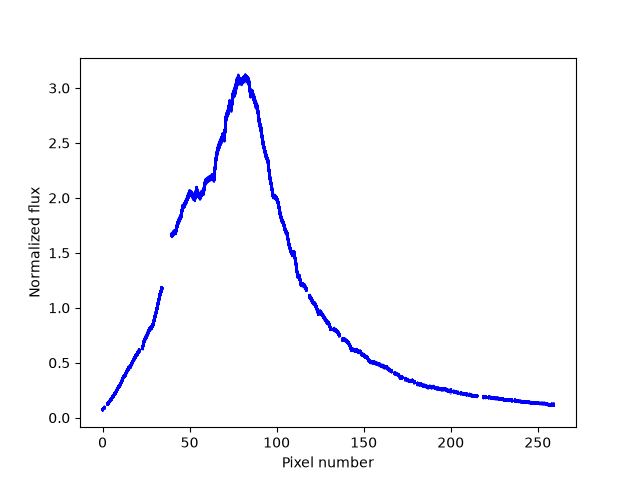

In [30]:
plt.figure()
for i in s1_norm[::100]:
    plt.plot(i,'b',alpha=0.5)
plt.xlabel("Pixel number")
plt.ylabel("Normalized flux")
plt.show()

Perhaps a bad pixel at 202 but otherwise looks OK

In [11]:
plt.close("all")

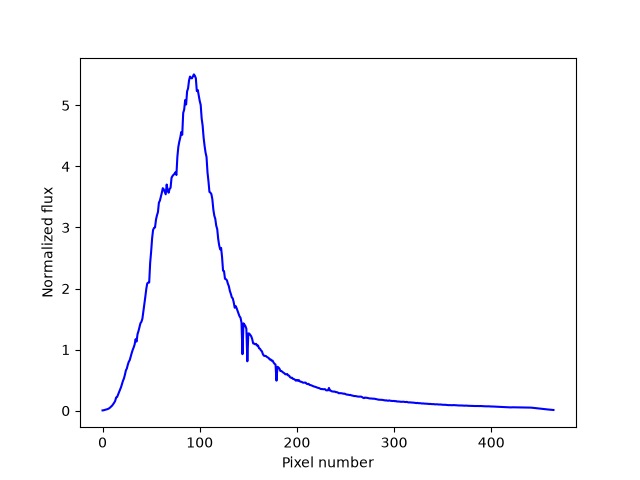

In [12]:
ref_frame = np.nanmedian(s1_norm,axis=0)

nframes = len(s1)

plt.figure()
plt.plot(ref_frame,color='b')
plt.xlabel("Pixel number")
plt.ylabel("Normalized flux")
plt.show()

Cleaning cosmics iteratively for the first time

<IPython.core.display.Javascript object>


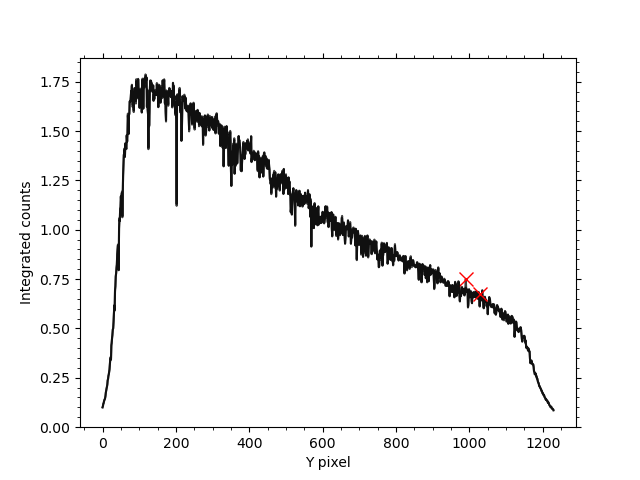

Post-cleaning


<IPython.core.display.Javascript object>


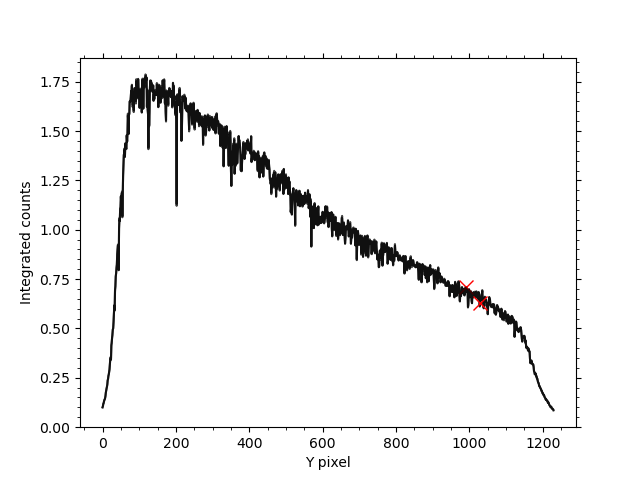

In [15]:
plt.close("all")

cleaned_flux = s1.copy()
cleaned_err = e1.copy()

ref_frame = np.nanmedian(cleaned_flux,axis=0)

cosmic_frames,cosmic_pixels = c.find_cosmic_frames(cleaned_flux,ref_frame,clip=10,mad=False,verbose=False,\
                                                       ignore_edges=10)

c.check_cosmic_frames(wc.normalise(cleaned_flux),cosmic_frames,cosmic_pixels,single_plot=True)

cleaned_flux,cleaned_err = c.replace_cosmics(cleaned_flux,cleaned_err,cosmic_frames,cosmic_pixels,\
                                             replace_with_nans=False)

print("Post-cleaning")
c.check_cosmic_frames(wc.normalise(cleaned_flux),cosmic_frames,cosmic_pixels,single_plot=True)

I actually don't think that it is worth the cosmic clipping here.

In [16]:
fwhm = pickle.load(open(f"../../../../../data/reduction{reductionNo}/pickled_objects/fwhm_1.pickle","rb"))
xpos = pickle.load(open(f"../../../../../data/reduction{reductionNo}/pickled_objects/x_positions_1.pickle","rb"))
sky = pickle.load(open(f"../../../../../data/reduction{reductionNo}/pickled_objects/background_avg_star1.pickle","rb"))

fwhm_norm = (fwhm-fwhm.mean())/fwhm.std()
xpos_norm = (xpos.sum(axis=1)-xpos.sum(axis=1).mean())/xpos.sum(axis=1).std()
sky_norm = (sky.sum(axis=1)-sky.sum(axis=1).mean())/sky.sum(axis=1).std()

In [17]:
fwhm_outliers = ~((fwhm_norm <= 3*np.std(fwhm_norm)) & (fwhm_norm >= -3*np.std(fwhm_norm)))
xpos_outliers = ~((xpos_norm <= 3*np.std(xpos_norm)) & (xpos_norm >= -3*np.std(xpos_norm)))
sky_outliers = ~((sky_norm <= 3*np.std(sky_norm)) & (sky_norm >= -3*np.std(sky_norm)))

In [18]:
all_outliers = fwhm_outliers.astype(int) + xpos_outliers.astype(int) + sky_outliers.astype(int)
common_outliers = all_outliers >= 2

<IPython.core.display.Javascript object>


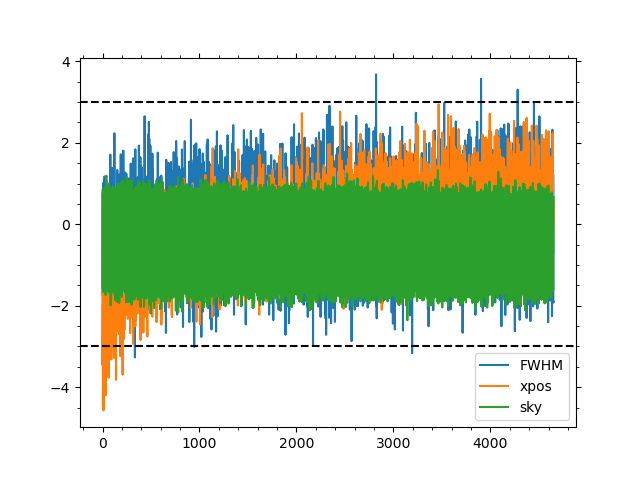

In [19]:
plt.figure()
plt.plot(fwhm_norm,label="FWHM")
plt.plot(xpos_norm,label="xpos")
plt.plot(sky_norm,label="sky")

# note, since these are standardized, 3 sigma outliers have a value > 3
plt.axhline(3,color='k',ls='--')
plt.axhline(-3,color='k',ls='--')

# plt.xlim(20730,20780)
plt.legend()
plt.show()


There are no consistently off data point so I think it's fair to assume there was no high gain antenna move here. 

However, the drops in sky background might need to be removed from the time-series of flux data points.

There is a fairly large shift in xpos